In [35]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/spam.csv', encoding='latin-1')

# Keep only required columns
df = df[['v1', 'v2']]
df.columns = ['label', 'text']

print("Dataset shape:", df.shape)
display(df.head())

df.info()

display(df.describe(include='all'))

print("\nClass counts:")
print(df['label'].value_counts())

print("\nDuplicates:", df.duplicated().sum())
print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


,label,text
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30



Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Duplicates: 403

Missing values:
label    0
text     0
dtype: int64


The dataset contains 5,572 messages with label and text columns.



The original dataset has 4,825 ham messages and 747 spam messages, showing class imbalance.



There are 403 duplicate rows, which should be removed before modeling.



The text column contains messages of different lengths, including short messages and longer conversations. Extra unnamed columns from the original CSV are not needed.


In [36]:

# Remove missing values and duplicate messages
df = df.dropna(subset=['label', 'text']).copy()

df = df.drop_duplicates().reset_index(drop=True)

df['text'] = df['text'].astype(str)

print("Shape after cleaning:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())
print("\nClass counts after cleaning:")
print(df['label'].value_counts())


Shape after cleaning: (5169, 2)
Duplicates remaining: 0

Class counts after cleaning:
label
ham     4516
spam     653
Name: count, dtype: int64


In [37]:

# Feature 1: Character length
df['text_length'] = df['text'].str.len()

# Feature 2: Word count
df['word_count'] = df['text'].str.split().str.len()

# Feature 3: Currency symbol presence
df['has_currency_symbol'] = df['text'].str.contains(
    r'[$£€¥]', regex=True
)

# Feature 4: Uppercase ratio
df['uppercase_ratio'] = df['text'].apply(
    lambda x: sum(c.isupper() for c in x) /
    max(sum(c.isalpha() for c in x), 1)
)

display(df.head())

print("\nEngineered feature summary:")
display(df[['text_length', 'word_count',
            'has_currency_symbol', 'uppercase_ratio']].describe())

print("\nCurrency symbol counts:")
print(df['has_currency_symbol'].value_counts())


,label,text,text_length,word_count,has_currency_symbol,uppercase_ratio
0,ham,"Go until jurong point, crazy.. Available only ...",111,20,False,0.036145
1,ham,Ok lar... Joking wif u oni...,29,6,False,0.111111
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,False,0.103093
3,ham,U dun say so early hor... U c already then say...,49,11,False,0.060606
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13,False,0.042553



Engineered feature summary:


,text_length,word_count,uppercase_ratio
count,5169.000000,5169.000000,5169.000000
mean,78.977945,15.340685,0.089299
std,58.236293,11.068488,0.150500
min,2.000000,1.000000,0.000000
25%,36.000000,7.000000,0.033333
50%,60.000000,12.000000,0.050000
75%,117.000000,22.000000,0.081081
max,910.000000,171.000000,1.000000



Currency symbol counts:
has_currency_symbol
False    4934
True      235
Name: count, dtype: int64


In [38]:
Q1 = df['text_length'].quantile(0.25)
Q3 = df['text_length'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['text_length'] < lower_bound) |
    (df['text_length'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

display(outliers[['label', 'text_length', 'text']].head(10))


Q1: 36.0
Q3: 117.0
IQR: 81.0
Lower bound: -85.5
Upper bound: 238.5
Number of outliers: 66


,label,text_length,text
53,ham,291,Wow. I never realized that you were so embaras...
125,ham,244,"Just so that you know,yetunde hasn't sent mone..."
152,ham,384,"You are everywhere dirt, on the floor, the win..."
373,ham,300,I guess that's why you re worried. You must kn...
417,ham,248,Send this to ur friends and receive something ...
464,ham,298,Nothing. I meant that once the money enters yo...
541,ham,281,Imagine you finally get to sink into that bath...
698,ham,269,Height of Confidence: All the Aeronautics prof...
819,ham,372,"Sir, I have been late in paying rent for the p..."
862,ham,276,"see, i knew giving you a break a few times wou..."


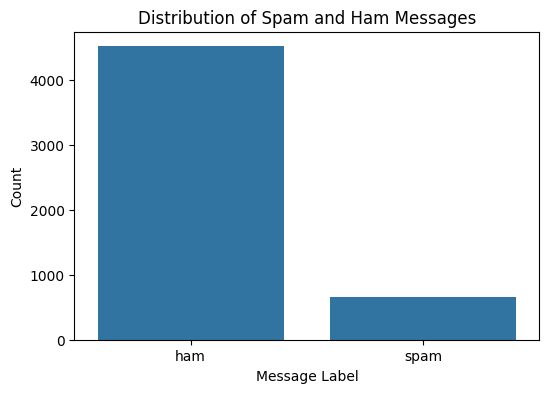

In [39]:

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label')

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Label")
plt.ylabel("Count")
plt.show()


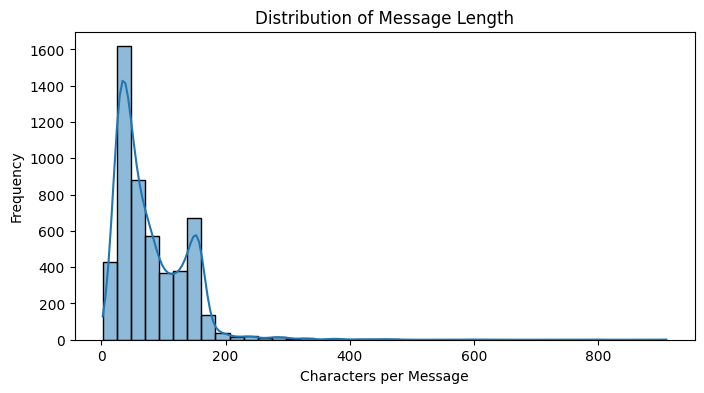

In [40]:

plt.figure(figsize=(8, 4))
sns.histplot(
    data=df,
    x='text_length',
    bins=40,
    kde=True
)

plt.title("Distribution of Message Length")
plt.xlabel("Characters per Message")
plt.ylabel("Frequency")
plt.show()


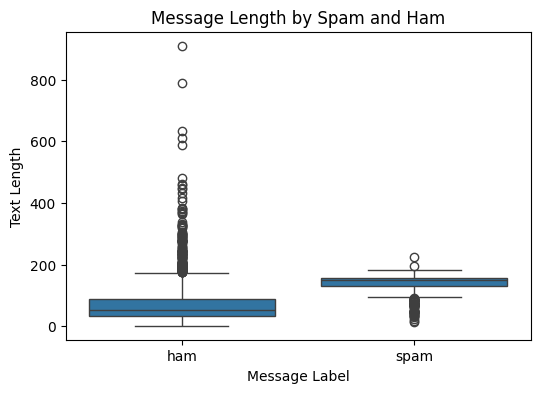

In [41]:

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='label', y='text_length')

plt.title("Message Length by Spam and Ham")
plt.xlabel("Message Label")
plt.ylabel("Text Length")
plt.show()


In [42]:

feature_summary = df.groupby('label').agg(
    avg_text_length=('text_length', 'mean'),
    median_text_length=('text_length', 'median'),
    avg_word_count=('word_count', 'mean'),
    avg_uppercase_ratio=('uppercase_ratio', 'mean'),
    currency_percentage=('has_currency_symbol', 'mean')
)

feature_summary['currency_percentage'] *= 100

display(feature_summary.round(2))


,avg_text_length,median_text_length,avg_word_count,avg_uppercase_ratio,currency_percentage
label,,,,,
ham,70.46,52.0,14.13,0.08,0.40
spam,137.89,149.0,23.68,0.17,33.23


Key Insights
1. Class imbalance: Ham messages represent approximately 87.37% of the cleaned dataset, while spam messages represent 12.63%.
2. Duplicate removal: The original dataset contained 403 duplicate rows. After removing duplicates, the dataset contains 5,169 unique rows.
3. Message length: Spam messages have an average length of approximately 137.89 characters, compared with 70.46 characters for ham messages.
4. Message length outliers: There are 66 messages longer than the IQR upper bound of 238.5 characters. These are retained because longer messages can be legitimate.
5. Currency symbols: Approximately 33.23% of spam messages contain a currency symbol, compared with approximately 0.40% of ham messages. This feature may be useful for classification, but it is not sufficient by itself to determine spam.

In [43]:

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Encode labels
df['label_num'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

X = df['text']
y = df['label_num']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Tokenization
tokenizer = Tokenizer(
    num_words=5000,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Padding
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=50
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=50
)

print("X_train:", X_train_pad.shape)
print("X_test:", X_test_pad.shape)


X_train: (4135, 50)
X_test: (1034, 50)


In [44]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

model = Sequential([
    Embedding(input_dim=5000, output_dim=32, input_length=50),
    LSTM(32),
    Dense(1, activation='sigmoid')
])

# Explicitly build the model
model.build(input_shape=(None, 50))

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,353 (657.63 KB)

 Trainable params: 168,353 (657.63 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:

history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/5
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9081 - loss: 0.2779 - val_accuracy: 0.9819 - val_loss: 0.1087
Epoch 2/5
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9800 - loss: 0.0834 - val_accuracy: 0.9867 - val_loss: 0.0548
Epoch 3/5
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9912 - loss: 0.0390 - val_accuracy: 0.9879 - val_loss: 0.0517
Epoch 4/5
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9952 - loss: 0.0240 - val_accuracy: 0.9879 - val_loss: 0.0450
Epoch 5/5
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9970 - loss: 0.0162 - val_accuracy: 0.9879 - val_loss: 0.0500


In [46]:

test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


Test Loss: 0.057354748249053955
Test Accuracy: 98.26 %


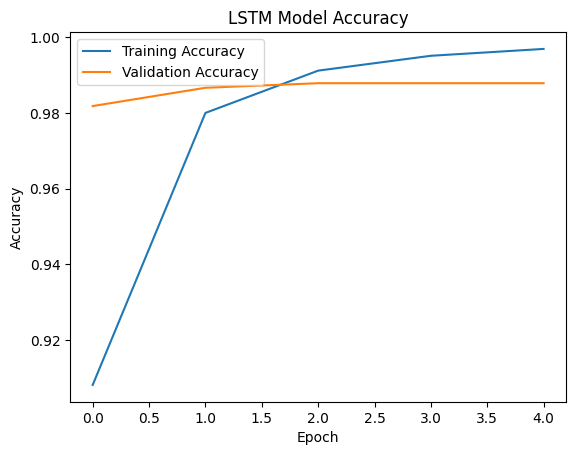

In [47]:

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
